In [53]:
import pandas as pd 
import numpy as np

from catboost import CatBoostClassifier, Pool


from sklearn.model_selection import train_test_split
from sklearn.metrics  import accuracy_score, confusion_matrix, classification_report, roc_auc_score

import seaborn as sns 
import matplotlib.pyplot as plt 

sns.set()


In [2]:
df = pd.read_csv('../data/titanic.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df2 = (
    df
        .assign(
            Age = df['Age'].fillna(-999)
        )

        .drop(['Cabin'],axis=1)
        .dropna()
)

In [5]:
df2.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C


In [11]:
X = df2.drop(['Survived', 'PassengerId', 'Name'], axis=1)
y = df2['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .30, stratify=y)

cat_features = [i for i in X.select_dtypes(include='str')]

In [55]:
train_pool = Pool(X_train, y_train, cat_features=cat_features)
valid_pool = Pool(X_test, y_test, cat_features= cat_features)


model = CatBoostClassifier(
    loss_function="Logloss",
    depth=4,
    learning_rate=0.05,
    iterations=50,
    eval_metric="AUC",
    custom_metric=["AUC", "Accuracy", "Precision", "BrierScore"],
    verbose=0,
    random_seed=42,
    allow_writing_files=False,
)

model.fit(train_pool, eval_set=[test_pool])

eval_results = model.get_evals_result()

In [62]:
model.get_best_score()['validation']['BrierScore']

0.1404472296507521

In [63]:
model.get_best_score()['validation']['Precision']

0.8170731707317073

In [64]:
model.get_best_score()['validation']['AUC']

0.866815210932858

Text(0, 0.5, 'AUC')

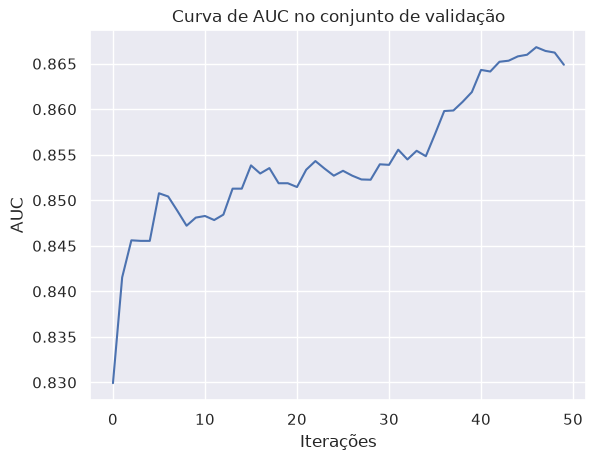

In [65]:
plt.plot(eval_results['validation']['AUC'])
plt.title('Curva de AUC no conjunto de validação')
plt.xlabel('Iterações')
plt.ylabel('AUC')

In [66]:
previsao_treino = model.predict(X_train)
previsao_test = model.predict(X_test)

acuracia_treino = accuracy_score(y_train, previsao_treino)
acuracia_teste = accuracy_score(y_test, previsao_test)

print(f'Acuracia de treino {acuracia_treino}')
print(f'Acuracia de teste {acuracia_teste}')



Acuracia de treino 0.8585209003215434
Acuracia de teste 0.8052434456928839


In [67]:
roc_treino = roc_auc_score(y_train, previsao_treino)
roc_teste = roc_auc_score(y_test, previsao_test)


print(f'roc de treino {roc_treino}')
print(f'roc de teste {acuracia_teste}')

roc de treino 0.8247111344537815
roc de teste 0.8052434456928839
